=================== OPTIMIZERS COMPARISON TABLE ===================
                   Loss  Accuracy  Precision    Recall        F1
Batch GD       0.677289  0.597015        0.5  0.222222  0.307692
SGD            0.679251  0.597015        0.5  0.222222  0.307692
Mini-Batch GD  0.680558  0.597015        0.5  0.222222  0.307692
RMSprop        0.681406  0.597015        0.5  0.222222  0.307692
Adam           0.680863  0.597015        0.5  0.222222  0.307692


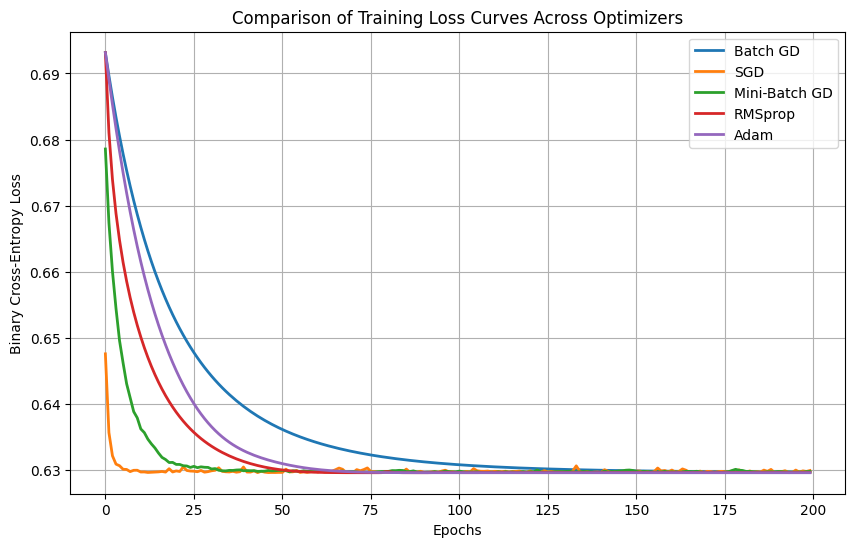

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load Data & Preprocessing (Titanic Dataset)
df = pd.read_csv('tested.csv')

features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
df = df[features + ['Survived']].dropna()

X = df[features].values
y = df['Survived'].values.reshape(-1, 1)

# Train / Test Split
np.random.seed(42)
indices = np.random.permutation(len(X))
split = int(0.8 * len(X))
X_train, X_test = X[indices[:split]], X[indices[split:]]
y_train, y_test = y[indices[:split]], y[indices[split:]]

# Standardization
mean = X_train.mean(axis=0)
std = X_train.std(axis=0) + 1e-8
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# Add Bias Term
X_train_b = np.c_[np.ones((X_train.shape[0], 1)), X_train]
X_test_b = np.c_[np.ones((X_test.shape[0], 1)), X_test]

# 2. Helper Functions
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def compute_loss(y_true, y_pred):
    eps = 1e-15
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

def evaluate_metrics(y_true, y_prob):
    y_pred = (y_prob >= 0.5).astype(int)
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    return {
        "Loss": compute_loss(y_true, y_prob),
        "Accuracy": (tp + tn) / len(y_true),
        "Precision": tp / (tp + fp + 1e-15),
        "Recall": tp / (tp + fn + 1e-15),
        "F1": 2 * tp / (2 * tp + fp + fn + 1e-15)
    }

m, n = X_train_b.shape
epochs = 200  # حددنا 200 دورة لتوحيد المقارنة
results_summary = {}
loss_histories = {}

# ==========================================
# 1. Batch Gradient Descent
# ==========================================
w = np.zeros((n, 1))
lr = 0.1
loss_history = []
for _ in range(epochs):
    y_pred = sigmoid(X_train_b @ w)
    grad = (1 / m) * (X_train_b.T @ (y_pred - y_train))
    w -= lr * grad
    loss_history.append(compute_loss(y_train, y_pred))
loss_histories['Batch GD'] = loss_history
results_summary['Batch GD'] = evaluate_metrics(y_test, sigmoid(X_test_b @ w))

# ==========================================
# 2. Stochastic Gradient Descent (SGD)
# ==========================================
w = np.zeros((n, 1))
lr = 0.01
loss_history = []
for _ in range(epochs):
    indices = np.random.permutation(m)
    for i in indices:
        xi = X_train_b[i:i+1]
        yi = y_train[i:i+1]
        y_pred = sigmoid(xi @ w)
        grad = xi.T @ (y_pred - yi)
        w -= lr * grad
    epoch_preds = sigmoid(X_train_b @ w)
    loss_history.append(compute_loss(y_train, epoch_preds))
loss_histories['SGD'] = loss_history
results_summary['SGD'] = evaluate_metrics(y_test, sigmoid(X_test_b @ w))

# ==========================================
# 3. Mini-Batch Gradient Descent
# ==========================================
w = np.zeros((n, 1))
lr = 0.05
batch_size = 32
loss_history = []
for _ in range(epochs):
    indices = np.random.permutation(m)
    X_shuff = X_train_b[indices]
    y_shuff = y_train[indices]
    for i in range(0, m, batch_size):
        xb = X_shuff[i:i+batch_size]
        yb = y_shuff[i:i+batch_size]
        y_pred = sigmoid(xb @ w)
        grad = (1 / len(xb)) * (xb.T @ (y_pred - yb))
        w -= lr * grad
    epoch_preds = sigmoid(X_train_b @ w)
    loss_history.append(compute_loss(y_train, epoch_preds))
loss_histories['Mini-Batch GD'] = loss_history
results_summary['Mini-Batch GD'] = evaluate_metrics(y_test, sigmoid(X_test_b @ w))

# ==========================================
# 4. RMSprop
# ==========================================
w = np.zeros((n, 1))
s = np.zeros((n, 1))
lr = 0.01
beta = 0.9
eps_val = 1e-8
loss_history = []
for _ in range(epochs):
    y_pred = sigmoid(X_train_b @ w)
    grad = (1 / m) * (X_train_b.T @ (y_pred - y_train))
    s = beta * s + (1 - beta) * (grad ** 2)
    w -= (lr / (np.sqrt(s) + eps_val)) * grad
    loss_history.append(compute_loss(y_train, y_pred))
loss_histories['RMSprop'] = loss_history
results_summary['RMSprop'] = evaluate_metrics(y_test, sigmoid(X_test_b @ w))

# ==========================================
# 5. Adam
# ==========================================
w = np.zeros((n, 1))
v = np.zeros((n, 1))
s = np.zeros((n, 1))
lr = 0.01
beta1 = 0.9
beta2 = 0.999
eps_val = 1e-8
loss_history = []
for t in range(1, epochs + 1):
    y_pred = sigmoid(X_train_b @ w)
    grad = (1 / m) * (X_train_b.T @ (y_pred - y_train))
    v = beta1 * v + (1 - beta1) * grad
    s = beta2 * s + (1 - beta2) * (grad ** 2)
    v_corr = v / (1 - (beta1 ** t))
    s_corr = s / (1 - (beta2 ** t))
    w -= (lr / (np.sqrt(s_corr) + eps_val)) * v_corr
    loss_history.append(compute_loss(y_train, y_pred))
loss_histories['Adam'] = loss_history
results_summary['Adam'] = evaluate_metrics(y_test, sigmoid(X_test_b @ w))

# ==========================================
# Print Comparison Table & Plot Results
# ==========================================
print("=================== OPTIMIZERS COMPARISON TABLE ===================")
comparison_df = pd.DataFrame(results_summary).T
print(comparison_df.to_string())
print("===================================================================")

# Plotting Combined Loss Curves
plt.figure(figsize=(10, 6))
for name, history in loss_histories.items():
    plt.plot(range(epochs), history, label=name, linewidth=2)

plt.title('Comparison of Training Loss Curves Across Optimizers')
plt.xlabel('Epochs')
plt.ylabel('Binary Cross-Entropy Loss')
plt.legend()
plt.grid(True)
plt.show()